In [1]:
import pandas as pd
import numpy as np

In [2]:
merchant_df = pd.read_csv("../data/curated/merchant_curated.csv", index_col= False)
merchant_df.columns
# merchant_df.head()


Index(['Unnamed: 0', 'merchant_abn', 'name', 'primary_category',
       'category_code', 'take_rate', 'fraud_count', 'avg_fraud_probability',
       'max_fraud_probability', 'min_fraud_probability'],
      dtype='object')

In [3]:
category_df = merchant_df.copy()

# 1. Primarily standardising the strings for the "primary_category" column 
# Ensure string dtype for regex ops
category_df['primary_category'] = category_df['primary_category'].astype(str)
category_df['category_code']   = category_df['category_code'].astype('object')

# Normalize quotes/parentheses & spaces a bit (keeps previous cleaning consistent)
category_df['primary_category'] = (
    category_df['primary_category']
      .str.replace(r'[()"“”]', '', regex=True)     # drop quotes & parentheses
      .str.replace('\u00a0', ' ')                   # NBSP -> space
      .str.replace(" ", "")
      .str.strip()
)

category_df.tail(5)

,Unnamed: 0,merchant_abn,name,primary_category,category_code,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability
4021,4021,99938978285,Elit Dictum Eu Ltd,"opticians,opticalgoods,andeyeglasses",NaN,4.50,0,0.0,0.0,0.0
4022,4022,99974311662,Mollis LLP,"books,periodicals,andnewspapers",NaN,3.17,0,0.0,0.0,0.0
4023,4023,99976658299,Sociosqu Corp.,"shoeshops,a",NaN,6.57,0,0.0,0.0,0.0
4024,4024,99987905597,Commodo Hendrerit LLC,nan,a,6.82,0,0.0,0.0,0.0
4025,4025,99990536339,Massa PC,"motorvehiclesuppliesandnewparts,e",NaN,0.18,0,0.0,0.0,0.0


In [4]:
# 2. Replace entries that are empty, commas, or just whitespace with NaN
category_df['primary_category'] = category_df['primary_category'].replace(
    to_replace=r'^(?:\s*|,|nan)$',  # regex for empty/whitespace/, or literal 'nan'
    value=np.nan,
    regex=True
)
category_df.tail(5)

,Unnamed: 0,merchant_abn,name,primary_category,category_code,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability
4021,4021,99938978285,Elit Dictum Eu Ltd,"opticians,opticalgoods,andeyeglasses",NaN,4.50,0,0.0,0.0,0.0
4022,4022,99974311662,Mollis LLP,"books,periodicals,andnewspapers",NaN,3.17,0,0.0,0.0,0.0
4023,4023,99976658299,Sociosqu Corp.,"shoeshops,a",NaN,6.57,0,0.0,0.0,0.0
4024,4024,99987905597,Commodo Hendrerit LLC,NaN,a,6.82,0,0.0,0.0,0.0
4025,4025,99990536339,Massa PC,"motorvehiclesuppliesandnewparts,e",NaN,0.18,0,0.0,0.0,0.0


In [5]:
# 3. If the category_code are accidently read in to the primary_category column, put it back to cateogry_code
# ---- MOVE TRAILING LETTER CODE FROM primary_category -> category_code ----
# Mask: category_code is NaN AND primary_category ends with ", <lowercase letter>"
mask = category_df['category_code'].isna() & category_df['primary_category'].str.contains(
    r'(?:,|\s)\s*[a-z]\s*$', na=False
)

# Extract the letter and set as category_code
category_df.loc[mask, 'category_code'] = (
    category_df.loc[mask, 'primary_category'].str.extract(r'([a-z])\s*$', expand=False).str.lower()
)

# category_df 


# Remove the trailing ", <letter>" from primary_category and tidy punctuation/space
category_df.loc[mask, 'primary_category'] = (
    category_df.loc[mask, 'primary_category']
      .str.replace(r'[, ]*[a-z]\s*$', '', regex=True)  # drop the trailing letter blob
      .str.replace(r'\s*,\s*', ', ', regex=True)       # neat comma spacing
      .str.replace(r',\s*,+', ', ', regex=True)        # collapse double commas
      .str.replace(r'\s+', ' ', regex=True)            # collapse spaces
      .str.strip(' ,')
      .replace('', np.nan)                             # empty -> NaN
)


# (Optional) sanity check: how many rows were fixed
moved_rows = int(mask.sum())
print(f"Moved single-letter category codes from primary_category to category_code: {moved_rows}")

category_df

Moved single-letter category codes from primary_category to category_code: 691


,Unnamed: 0,merchant_abn,name,primary_category,category_code,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability
0,0,10023283211,Felis Limited,"furniture,homefurnishingsandequipmentshops,and...",NaN,0.18,0,0.0,0.0,0.0
1,1,10142254217,Arcu Ac Orci Corporation,"cable,satellite,andotherpaytelevisionandradios...",b,4.22,0,0.0,0.0,0.0
2,2,10165489824,Nunc Sed Company,"jewelry,watch,clock,andsilverwareshops",b,4.40,0,0.0,0.0,0.0
3,3,10187291046,Ultricies Dignissim Lacus Foundation,"watch,clock,andjewelryrepairshops",b,3.29,0,0.0,0.0,0.0
4,4,10192359162,Enim Condimentum PC,"musicshops-musicalinstruments,pianos,andsheetm...",a,6.33,0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
4021,4021,99938978285,Elit Dictum Eu Ltd,"opticians,opticalgoods,andeyeglasses",NaN,4.50,0,0.0,0.0,0.0
4022,4022,99974311662,Mollis LLP,"books,periodicals,andnewspapers",NaN,3.17,0,0.0,0.0,0.0
4023,4023,99976658299,Sociosqu Corp.,shoeshops,a,6.57,0,0.0,0.0,0.0
4024,4024,99987905597,Commodo Hendrerit LLC,NaN,a,6.82,0,0.0,0.0,0.0


In [6]:
# 4. Create a new column "new_category_code" based on new rule
import numpy as np

# define your conditions
category_df['take_rate'] = pd.to_numeric(category_df['take_rate'], errors='coerce')

bins = [-np.inf, 0.5, 1.4, 3.1, 5.5, np.inf]
labels = ['e', 'd', 'c', 'b', 'a']

category_df['new_category_code'] = pd.cut(category_df['take_rate'], bins=bins, labels=labels, right=False)

# ensure choices are object dtype so np.nan (float) is compatible
category_df[['take_rate', 'new_category_code']].head()

category_df

,Unnamed: 0,merchant_abn,name,primary_category,category_code,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability,new_category_code
0,0,10023283211,Felis Limited,"furniture,homefurnishingsandequipmentshops,and...",NaN,0.18,0,0.0,0.0,0.0,e
1,1,10142254217,Arcu Ac Orci Corporation,"cable,satellite,andotherpaytelevisionandradios...",b,4.22,0,0.0,0.0,0.0,b
2,2,10165489824,Nunc Sed Company,"jewelry,watch,clock,andsilverwareshops",b,4.40,0,0.0,0.0,0.0,b
3,3,10187291046,Ultricies Dignissim Lacus Foundation,"watch,clock,andjewelryrepairshops",b,3.29,0,0.0,0.0,0.0,b
4,4,10192359162,Enim Condimentum PC,"musicshops-musicalinstruments,pianos,andsheetm...",a,6.33,0,0.0,0.0,0.0,a
...,...,...,...,...,...,...,...,...,...,...,...
4021,4021,99938978285,Elit Dictum Eu Ltd,"opticians,opticalgoods,andeyeglasses",NaN,4.50,0,0.0,0.0,0.0,b
4022,4022,99974311662,Mollis LLP,"books,periodicals,andnewspapers",NaN,3.17,0,0.0,0.0,0.0,b
4023,4023,99976658299,Sociosqu Corp.,shoeshops,a,6.57,0,0.0,0.0,0.0,a
4024,4024,99987905597,Commodo Hendrerit LLC,NaN,a,6.82,0,0.0,0.0,0.0,a


In [7]:
# Analysis on "category_code" and "new_category_code"

nan_count = category_df['category_code'].isna().sum()
print(f"Number of rows with NaN in 'category_code': {nan_count}")

Number of rows with NaN in 'category_code': 1361


In [8]:
# Filter rows where both columns are not NaN
valid_rows = category_df.dropna(subset=['category_code', 'new_category_code'])

# Count how many matches
correct = (valid_rows['category_code'] == valid_rows['new_category_code']).sum()
total = len(valid_rows)

# Compute accuracy
accuracy = correct / total * 100 if total > 0 else 0

print(f"Accuracy (excluding NaN rows): {accuracy:.2f}%")
print(f"Matched: {correct} / {total}")


Accuracy (excluding NaN rows): 99.96%
Matched: 2664 / 2665


In [9]:
# 4. Category Count Dataframe
# Continue with your cleaned column (or re-run your aggregation on df)
category_count_df = (
    category_df.groupby('primary_category', dropna=False)
      .agg(merchant_count=('merchant_abn', 'nunique'))
      .reset_index()
      .sort_values('merchant_count', ascending=False)
)

category_count_df = category_count_df.reset_index(drop=True)
category_count_df

,primary_category,merchant_count
0,NaN,976
1,artistsupplyandcraftshops,152
2,"digitalgoods:books,movies,music",148
3,tentandawningshops,147
4,"computerprogramming,dataprocessing,andintegrat...",143
5,"furniture,homefurnishingsandequipmentshops,and...",139
6,"computers,computerperipheralequipment,andsoftware",138
7,shoeshops,138
8,"cable,satellite,andotherpaytelevisionandradios...",136
9,"floristssupplies,nurserystock,andflowers",134


In [10]:
# Check if each category_code is mapped to more than one primary_category => Since we don't have the 
mapping_check = (
    category_df.groupby('category_code')['primary_category']
      .nunique()
      .reset_index(name='distinct_primary_category_count')
      .sort_values('distinct_primary_category_count', ascending=False)
)

mapping_check

,category_code,distinct_primary_category_count
0,a,25
1,b,25
2,c,25
3,d,18
4,e,13


In [11]:
from pyspark.sql import SparkSession

try:
    spark
except NameError:
    spark = (SparkSession.builder
             .appName("Merchant Categories Data")
             .config("spark.driver.memory", "8g")
             .config("spark.sql.execution.arrow.pyspark.enabled", "true")
             .getOrCreate())

spark

25/10/10 18:30:16 WARN Utils: Your hostname, I-Spider-Spacy-Y.local resolves to a loopback address: 127.0.0.1; using 10.13.115.158 instead (on interface en0)
25/10/10 18:30:16 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/10/10 18:30:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
25/10/10 18:30:17 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


In [12]:
merchant_feature_df = pd.read_csv('../data/curated/merchant_feature_engineering.csv')
merchant_feature_df

,Unnamed: 0,merchant_abn,active_months,first_year_month,last_year_month,sum_tx_count,avg_monthly_tx_count,overall_avg_tx_value,sum_total_dollar_value,avg_monthly_total_dollar_value,...,pos_month_share,inactivity_rate,cagr_overall,unique_users_all_periods,repeat_customers,repeat_share,total_tertiary_ratio,total_yr12_completion_ratio,median_tot_prsnl_inc_weekly,tx_per_customer
0,0,10142254217,10,2021-03,2021-12,1492,149.200000,38.791028,57876.214261,5787.621426,...,1.0,0.0,0.899536,2510,148,0.058964,5.201302,40.076130,792.818182,1.061076
1,1,10187291046,10,2021-03,2021-12,165,16.500000,113.160388,18671.463953,1867.146395,...,1.0,0.0,0.572070,296,1,0.003378,4.763940,39.364555,791.125000,1.003922
2,2,10192359162,10,2021-03,2021-12,183,18.300000,463.048006,84737.785125,8473.778512,...,1.0,0.0,1.485803,329,1,0.003040,5.141724,40.423854,818.410256,1.003676
3,3,10206519221,10,2021-03,2021-12,4842,484.200000,38.125672,184604.501867,18460.450187,...,1.0,0.0,1.236993,7118,1219,0.171256,5.134904,39.698740,790.694284,1.192560
4,4,10255988167,10,2021-03,2021-12,428,42.800000,398.225257,170440.410057,17044.041006,...,1.0,0.0,1.387497,719,14,0.019471,5.027784,39.064928,792.150502,1.018739
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4401,4401,99807059634,7,2021-03,2021-12,8,1.142857,3569.267443,28554.139546,4079.162792,...,1.0,0.0,0.491764,13,0,0.000000,4.216821,37.618957,860.818182,1.000000
4402,4402,99845294286,10,2021-03,2021-12,408,40.800000,1740.244259,710019.657724,71001.965772,...,1.0,0.0,0.333838,701,6,0.008559,5.005259,39.611097,784.335017,1.005076
4403,4403,99861963809,10,2021-03,2021-12,150,15.000000,114.288832,17143.324769,1714.332477,...,1.0,0.0,2.066670,272,0,0.000000,4.894986,40.012060,785.031674,1.000000
4404,4404,99904689266,10,2021-03,2021-12,2900,290.000000,104.301250,302473.624221,30247.362422,...,1.0,0.0,1.128091,4550,500,0.109890,5.093312,39.635040,790.404535,1.116143


In [13]:
type(category_df.iloc[0,0])

numpy.int64

In [14]:

merchant_feature_df['merchant_abn'] = merchant_feature_df['merchant_abn'].astype(int)
type(merchant_feature_df.iloc[0,0])

numpy.int64

In [15]:
merchant_feature_engineered_df = pd.merge(category_df, merchant_feature_df, on='merchant_abn', how='left')
merchant_feature_engineered_df = merchant_feature_engineered_df[[
        'merchant_abn', 'name', 'new_category_code', 'primary_category',
        
        'take_rate', 'fraud_count', 'avg_fraud_probability', 'max_fraud_probability', 'min_fraud_probability', 

        'active_months', 'first_year_month', 'last_year_month',

        'sum_tx_count', 'avg_monthly_tx_count', 'overall_avg_tx_value',
        'sum_total_dollar_value', 'avg_monthly_total_dollar_value', 'avg_monthly_unique_customers', 
        
        'std_slope', 'trend_nrmse', 'r2',
        'pos_month_share', 'inactivity_rate', 'cagr_overall',

        'repeat_customers','repeat_share', 
        
        'unique_users_all_periods', 'total_tertiary_ratio', 'median_tot_prsnl_inc_weekly',
       'total_yr12_completion_ratio', 'tx_per_customer']]


In [16]:
# Create a segment_code column with the manually defined segmentation
# Segmention: 
# 1: Services: NaN: 0
# 2. Tech and digital services:  4, 6, 8, 22
# 3. Art / Entertainment / Education: 1, 2, 14, 15, 17, 18, 24
# 4. Fashion / Personal: 3, 5, 9, 19, 21
# 5. Home / Living: 7, 10, 11, 12, 13, 16, 20, 23, 25 


seg_dict = {1: "services", 
            2: "Tech & Digital Services", 
            3: "Art ,Entertainment & Education", 
            4: "Fashion & Personal ", 
            5: "Home & Living"}

seg_1 = [0]
seg_2 = [4, 6, 8, 22]
seg_3 = [1, 2, 14, 15, 17, 18, 24]
seg_4 = [7, 10, 11, 12, 13, 16, 20, 23, 25]
seg_5 = [3, 5, 9, 19, 21]

In [17]:


# --- Build two mappings: one for segment number, one for segment name ---
segment_num_map = {}
segment_name_map = {}

# --- Build mapping from primary_category to segmentation ---
segment_mapping = {}

for idx in seg_1:
    cat = category_count_df.loc[idx, 'primary_category']
    segment_num_map[cat] = 1
    segment_name_map[cat] = seg_dict[1]

for idx in seg_2:
    cat = category_count_df.loc[idx, 'primary_category']
    segment_num_map[cat] = 2
    segment_name_map[cat] = seg_dict[2]

for idx in seg_3:
    cat = category_count_df.loc[idx, 'primary_category']
    segment_num_map[cat] = 3
    segment_name_map[cat] = seg_dict[3]

for idx in seg_4:
    cat = category_count_df.loc[idx, 'primary_category']
    segment_num_map[cat] = 4
    segment_name_map[cat] = seg_dict[4]

for idx in seg_5:
    cat = category_count_df.loc[idx, 'primary_category']
    segment_num_map[cat] = 5
    segment_name_map[cat] = seg_dict[5]

# --- Apply mappings to merchant_feature_engineered_df ---
merchant_feature_engineered_df['segment_code'] = (
    merchant_feature_engineered_df['primary_category']
    .map(segment_num_map)
)

merchant_feature_engineered_df['segmentation'] = (
    merchant_feature_engineered_df['primary_category']
    .map(segment_name_map)
)

# --- Fill missing (unmapped) ones ---
merchant_feature_engineered_df['segment_code'] = merchant_feature_engineered_df['segment_code'].fillna(0).astype(int)
merchant_feature_engineered_df['segmentation'] = merchant_feature_engineered_df['segmentation'].fillna('Unclassified')

# --- Quick check ---
merchant_feature_engineered_df[['primary_category', 'segment_code', 'segmentation']].head(10)


,primary_category,segment_code,segmentation
0,"furniture,homefurnishingsandequipmentshops,and...",5,Home & Living
1,"cable,satellite,andotherpaytelevisionandradios...",2,Tech & Digital Services
2,"jewelry,watch,clock,andsilverwareshops",4,Fashion & Personal
3,"watch,clock,andjewelryrepairshops",4,Fashion & Personal
4,"musicshops-musicalinstruments,pianos,andsheetm...",3,"Art ,Entertainment & Education"
5,"gift,card,novelty,andsouvenirshops",4,Fashion & Personal
6,"computers,computerperipheralequipment,andsoftware",2,Tech & Digital Services
7,NaN,1,services
8,"computerprogramming,dataprocessing,andintegrat...",2,Tech & Digital Services
9,"furniture,homefurnishingsandequipmentshops,and...",5,Home & Living


In [18]:
merchant_feature_engineered_df.to_csv("../data/curated/merchant_overall.csv", index=False)

In [19]:
merchant_feature_engineered_df.columns

Index(['merchant_abn', 'name', 'new_category_code', 'primary_category',
       'take_rate', 'fraud_count', 'avg_fraud_probability',
       'max_fraud_probability', 'min_fraud_probability', 'active_months',
       'first_year_month', 'last_year_month', 'sum_tx_count',
       'avg_monthly_tx_count', 'overall_avg_tx_value',
       'sum_total_dollar_value', 'avg_monthly_total_dollar_value',
       'avg_monthly_unique_customers', 'std_slope', 'trend_nrmse', 'r2',
       'pos_month_share', 'inactivity_rate', 'cagr_overall',
       'repeat_customers', 'repeat_share', 'unique_users_all_periods',
       'total_tertiary_ratio', 'median_tot_prsnl_inc_weekly',
       'total_yr12_completion_ratio', 'tx_per_customer', 'segment_code',
       'segmentation'],
      dtype='object')

## Viaualisation

In [20]:

# Continue with your cleaned column (or re-run your aggregation on df)
takerate_count_df = (
    category_df.groupby('new_category_code', dropna=False)
      .agg(merchant_count=('merchant_abn', 'nunique'))
      .reset_index()
      .sort_values('merchant_count', ascending=False)
)

takerate_count_df = takerate_count_df.reset_index(drop=True)
takerate_count_df

/var/folders/t1/72blqmh510s440mr2w_mkfbw0000gn/T/ipykernel_43956/656881488.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_df.groupby('new_category_code', dropna=False)


,new_category_code,merchant_count
0,a,1602
1,b,1353
2,c,921
3,d,97
4,e,53


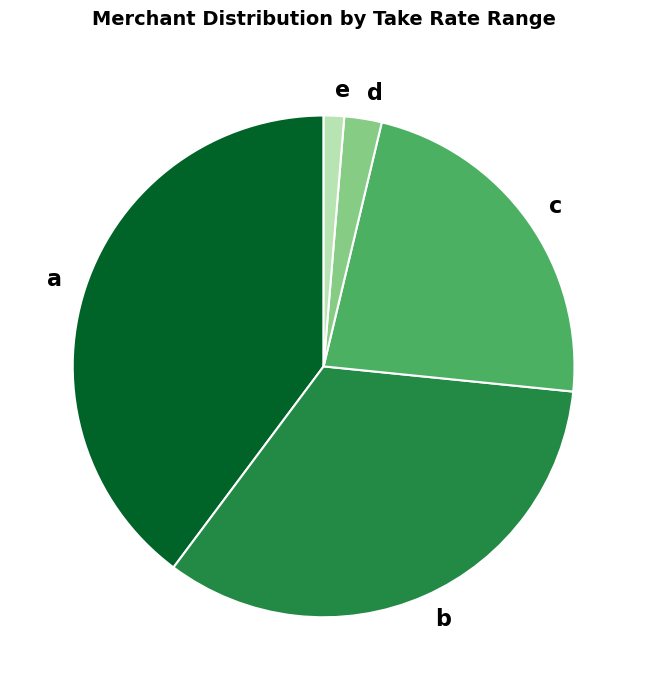

In [21]:
import matplotlib.pyplot as plt

# Map readable labels
takerate_count_df['label'] = takerate_count_df['new_category_code']

colors = plt.cm.Greens([0.9, 0.75, 0.6, 0.45, 0.3])

plt.figure(figsize=(7, 7))
wedges, texts = plt.pie(
    takerate_count_df['merchant_count'],
    labels=takerate_count_df['label'],
    colors=colors,
    startangle=90,
    textprops={'fontsize': 16, 'color': 'black'},   # ensure black text
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    labeldistance=1.1                             # small nudge outward
)

# (optional) make labels bold and add a faint white halo for readability
for t in texts:
    t.set_fontweight('bold')
    t.set_path_effects([])  # add halo if you like: [patheffects.withStroke(linewidth=3, foreground="white")]

plt.title("Merchant Distribution by Take Rate Range", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("../visualisations/Merchant_Take_Rate.png", transparent=True)
plt.show()


In [22]:
merchant_feature_engineered_df

,merchant_abn,name,new_category_code,primary_category,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability,active_months,...,cagr_overall,repeat_customers,repeat_share,unique_users_all_periods,total_tertiary_ratio,median_tot_prsnl_inc_weekly,total_yr12_completion_ratio,tx_per_customer,segment_code,segmentation
0,10023283211,Felis Limited,e,"furniture,homefurnishingsandequipmentshops,and...",0.18,0,0.0,0.0,0.0,10.0,...,1.237597,164.0,0.060853,2695.0,5.146968,786.284681,39.566658,1.061907,5,Home & Living
1,10142254217,Arcu Ac Orci Corporation,b,"cable,satellite,andotherpaytelevisionandradios...",4.22,0,0.0,0.0,0.0,10.0,...,0.899536,148.0,0.058964,2510.0,5.201302,792.818182,40.076130,1.061076,2,Tech & Digital Services
2,10165489824,Nunc Sed Company,b,"jewelry,watch,clock,andsilverwareshops",4.40,0,0.0,0.0,0.0,1.0,...,NaN,0.0,0.000000,4.0,6.067568,893.333333,43.409973,1.000000,4,Fashion & Personal
3,10187291046,Ultricies Dignissim Lacus Foundation,b,"watch,clock,andjewelryrepairshops",3.29,0,0.0,0.0,0.0,10.0,...,0.572070,1.0,0.003378,296.0,4.763940,791.125000,39.364555,1.003922,4,Fashion & Personal
4,10192359162,Enim Condimentum PC,a,"musicshops-musicalinstruments,pianos,andsheetm...",6.33,0,0.0,0.0,0.0,10.0,...,1.485803,1.0,0.003040,329.0,5.141724,818.410256,40.423854,1.003676,3,"Art ,Entertainment & Education"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4021,99938978285,Elit Dictum Eu Ltd,b,"opticians,opticalgoods,andeyeglasses",4.50,0,0.0,0.0,0.0,10.0,...,1.189607,3280.0,0.288428,11372.0,5.091341,791.344444,39.812546,1.353744,4,Fashion & Personal
4022,99974311662,Mollis LLP,b,"books,periodicals,andnewspapers",3.17,0,0.0,0.0,0.0,10.0,...,1.356369,0.0,0.000000,116.0,4.997636,815.595745,40.376770,1.000000,3,"Art ,Entertainment & Education"
4023,99976658299,Sociosqu Corp.,a,shoeshops,6.57,0,0.0,0.0,0.0,10.0,...,1.205243,5047.0,0.363826,13872.0,5.131035,790.357590,39.895722,1.476091,4,Fashion & Personal
4024,99987905597,Commodo Hendrerit LLC,a,NaN,6.82,0,0.0,0.0,0.0,10.0,...,4.181318,2.0,0.012658,158.0,4.921412,752.860465,39.017504,1.007812,1,services


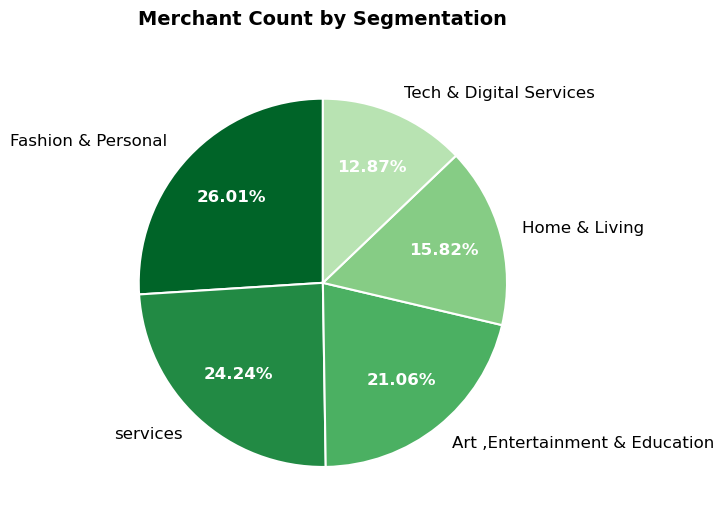

In [24]:
# Create Visualisations based on segematation merchant distribution 

import numpy as np
import matplotlib.pyplot as plt

# --- 1) Aggregate: merchant count per segmentation -------------------------
seg_count_df = (
    merchant_feature_engineered_df
        .assign(segmentation=lambda d: d['segmentation'].fillna('Unassigned').astype(str))
        .groupby('segmentation', as_index=False)
        .agg(merchant_count=('merchant_abn', 'nunique'))
        .sort_values('merchant_count', ascending=False)
)

# Optional: enforce an order if you use codes like a–e
# order = ['a','b','c','d','e','Unassigned']
# seg_count_df['segmentation'] = pd.Categorical(seg_count_df['segmentation'], order, ordered=True)
# seg_count_df = seg_count_df.sort_values('segmentation')

# --- 2) Pie chart -----------------------------------------------------------
vals   = seg_count_df['merchant_count'].to_numpy()
labels = seg_count_df['segmentation'].astype(str).to_numpy()
colors = plt.cm.Greens(np.linspace(0.9, 0.3, len(vals)))  # monotone palette

plt.figure(figsize=(7, 7))
wedges, texts, autotexts = plt.pie(
    vals,
    labels=labels,
    colors=colors,
    startangle=90,
    autopct='%1.2f%%',          # show percentages
    pctdistance=0.68,           # pull % inward to reduce overlap
    labeldistance=1.12,         # push labels outward
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)

# style % texts
for t in autotexts:
    t.set_color('white')
    t.set_fontweight('bold')

plt.title("Merchant Count by Segmentation", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("../visualisations/Merchant_Count_by_Segmentation.png", transparent=True)
plt.show()
